
# Module 3
## Lab 1: Gradient Descent

# Gradient Descent: A Quick Recap

We introduced **Gradient Descent** as a method to find the minimum of a loss function. It is the core optimization algorithm that powers a vast majority of **Machine Learning** and **Deep Learning** models.

---

### A Quick Recap of the Algorithm

The core idea of **Gradient Descent** is to iteratively take steps in the direction of the steepest descent of a function (our loss function) to find its minimum.

1. Start with a random initialization of the solution (model parameters or weights).
2. Incrementally change the solution by moving in the direction of the **negative gradient** of the loss function.
3. Repeat the previous step until some convergence criteria is met.

---

The key update equation for a weight or parameter ($w$) is:

$$
w_{k+1} \leftarrow w_k - \eta \nabla J
$$

Where:
- $w_k$ is the current weight.
- $\eta$ is the **learning rate**.
- $\nabla J$ is the **gradient of the loss function** $J$.


In this lab, we will discuss stochastic gradient descent, mini-batch gradient descent and batch gradient descent.


### Setting up the Environment and Data

First, let's import the necessary libraries and set a random seed for reproducibility.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

## Creating the Data

We'll generate some synthetic data that follows a **linear pattern**. Our true linear equation will be:

$$
y = 4 + 3x
$$

We will also add some **random noise** to the y values to simulate real-world data, which is rarely perfect.

Let's generate the data with:
- `y0 = 4` (intercept)
- `y1 = 3` (slope)

and add some noise to the data.


In [3]:
# We are creating data based on the equation y = 4 + 3x + noise

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

Here, np.random.rand(100, 1) creates 100 random numbers between 0 and 1. Multiplying by 2 scales this to be between 0 and 2. np.random.randn(100, 1) adds Gaussian noise (random fluctuations) to our y values.

Let's also plot the data we just created

Text(0, 0.5, 'y')

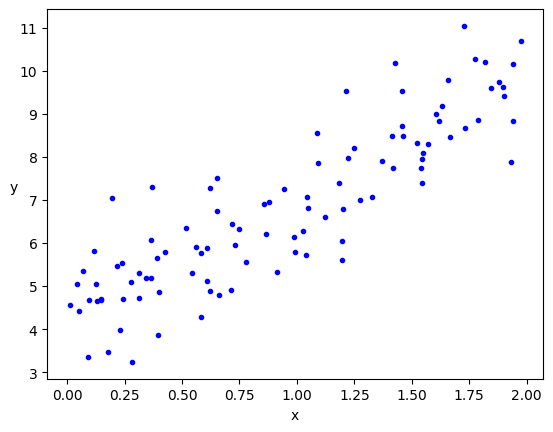

In [4]:
plt.plot(X, y, 'b.')
plt.xlabel('x')
plt.ylabel('y', rotation=0)

Our goal is to use Gradient Descent to find the original parameters (intercept = 4, slope = 3) just by looking at this scattered data.

## The Cost Function for Linear Regression

Before we can optimize, we need to define how we measure error. For **Linear Regression**, we use the **Mean Squared Error (MSE)** cost function. It measures the average squared difference between the model's predictions and the actual values.

The equation for the MSE cost function $J$ is:

$$
J(\theta) = \frac{1}{2m}  \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2
$$

Where:
- $m$ is the number of training examples.
- $\theta$ is our vector of model parameters (in our case, the intercept and the slope).
- $h_\theta(x^{(i)})$ is the prediction for the $i$-th example.
- $y^{(i)}$ is the true label for the $i$-th example.

The $\frac{1}{2}$ is included for convenience, as it simplifies the derivative calculation.


In [5]:
def cal_cost(theta, X, y):
    """Return the half mean-squared error: (1 / 2m) * sum((Xθ - y)^2)."""
    m = len(y)
    predictions = X @ theta
    return float(np.sum((predictions - y) ** 2) / (2 * m))


## The Gradient of the Cost Function

To use **Gradient Descent**, we need the partial derivatives of the cost function with respect to each parameter \(\theta_j\).

The general form of the gradient for **Linear Regression** is:

$$
\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}
$$

For our problem with one feature \(x\) and an intercept, we have two parameters: \(\theta_0\) (intercept) and \(\theta_1\) (slope). The updates will be:

$$
\theta_0 := \theta_0 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)
$$

$$
\theta_1 := \theta_1 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) \cdot x_1^{(i)}
$$

This can be written in a compact, **vectorized form**:

$$
\nabla J(\theta) = \frac{1}{m} X^T (X\theta - y)
$$


### Variant 1: Batch Gradient Descent

**Batch Gradient Descent** is the simplest variant. In each step, it calculates the gradient using the **entire training dataset**.

**Pros:**
- The convergence path is smooth and stable because the gradient is a true average over all data.

**Cons:**
- It is very slow and computationally expensive for large datasets.


In [6]:
def gradient_descent(X, y, theta, learning_rate=0.01, iterations=100):
    """Batch Gradient Descent: update parameters using the full dataset."""
    m = len(y)
    cost_history = np.zeros(iterations)
    theta_history = np.zeros((iterations, theta.size))

    for it in range(iterations):
        errors = X @ theta - y
        gradient = (X.T @ errors) / m
        theta = theta - learning_rate * gradient
        cost_history[it] = cal_cost(theta, X, y)
        theta_history[it, :] = theta.ravel()

    return theta, cost_history, theta_history


### Running Batch Gradient Descent

Let's run this for **1000 iterations** with a learning rate of **0.01**. We start with a random guess for our parameters (`y_pred`).

**Our model** is:
$$
y = \theta_0 + \theta_1 x
$$

**A crucial step:**
To handle the intercept term $\theta_0$ using matrix multiplication, we add a "dummy" feature $x_0 = 1$ to all our input samples. This is known as the **bias trick**.


In [7]:
lr = 0.01
n_iter = 1000

y_pred = np.random.randn(2,1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history, y_pred_history = gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 3.903
y_pred[1]: 3.046
Final error: 0.418


The learned parameters (3.903, 3.046) are very close to our original true values (4, 3)!

### Visualizing the Loss

Let's plot the error at each iteration. This is our "descent down the mountain".

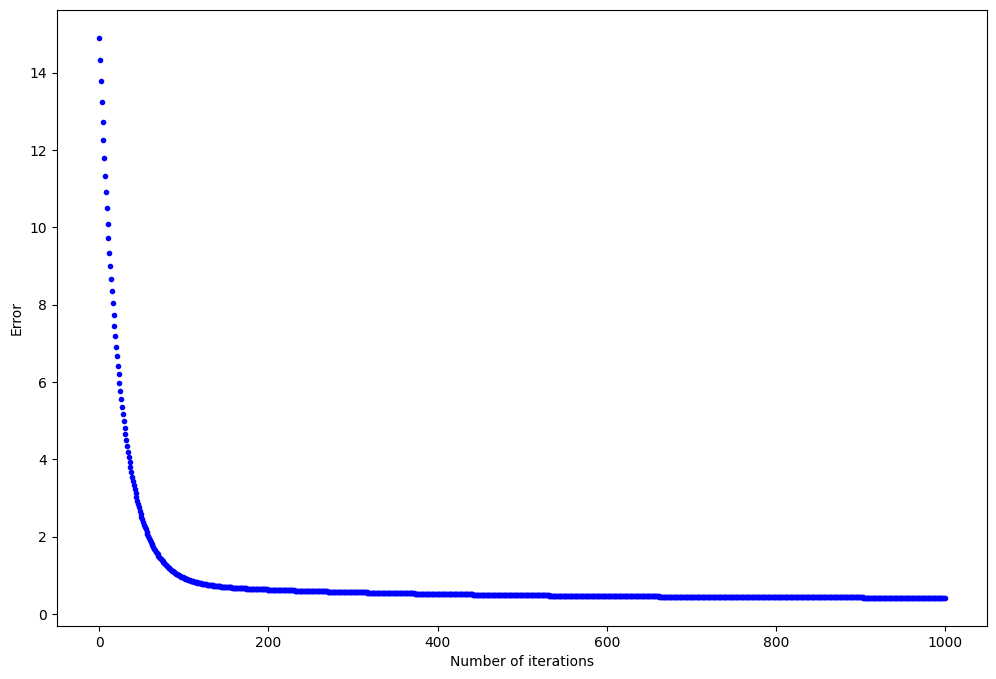

In [8]:
fig, ax = plt.subplots(figsize=(12,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')

ax.plot(range(n_iter), cost_history, 'b.')

Zooming in on the first 200 iterations shows how the error drops rapidly at first and then slows down as it approaches the minimum.

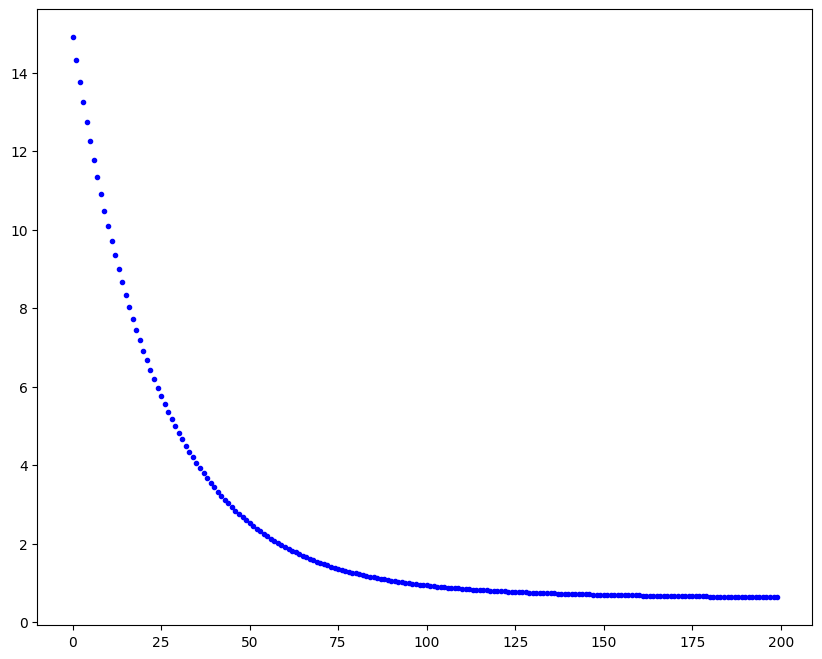

In [9]:
fig,ax = plt.subplots(figsize=(10,8))
ax.plot(range(200), cost_history[:200], 'b.')

The smooth curve is characteristic of Batch Gradient Descent.

### Variant 2: Stochastic Gradient Descent (SGD)

**Batch GD** is inefficient for large datasets. **SGD** addresses this by taking a gradient step based on **only one randomly chosen training example at a time**.

**Pros:**
- Extremely fast per step.
- Can help escape shallow local minima due to its random nature.

**Cons:**
- The path to the minimum is very noisy and erratic.
- It never truly "settles" at the minimum but bounces around it.


In [10]:
def stocashtic_gradient_descent(X, y, theta, learning_rate=0.01, iterations=10):
    """Stochastic Gradient Descent: update from one randomly selected row at a time.

    One epoch performs m single-example updates; cost is measured on the full
    dataset at the end of each epoch for a comparable loss curve.
    """
    m = len(y)
    cost_history = np.zeros(iterations)

    for epoch in range(iterations):
        for index in np.random.permutation(m):
            X_i = X[index:index + 1]
            y_i = y[index:index + 1]
            error = X_i @ theta - y_i
            gradient = X_i.T @ error
            theta = theta - learning_rate * gradient
        cost_history[epoch] = cal_cost(theta, X, y)

    return theta, cost_history


Let's run SGD. Because it updates parameters after each randomly selected observation, its learning rate is usually chosen more carefully than the batch learning rate. We use a modest value here and record the full-dataset loss after each epoch.

In [11]:
lr = 0.01
n_iter = 50
y_pred = np.random.randn(2, 1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history = stocashtic_gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.218
y_pred[1]: 2.769
Final error: 0.403


Again, the parameters are close to the true values, but notice the final error is higher and the parameters are slightly less accurate. This is due to the noisy nature of SGD.


### Visualizing the Loss

The loss curve for SGD is much more erratic.

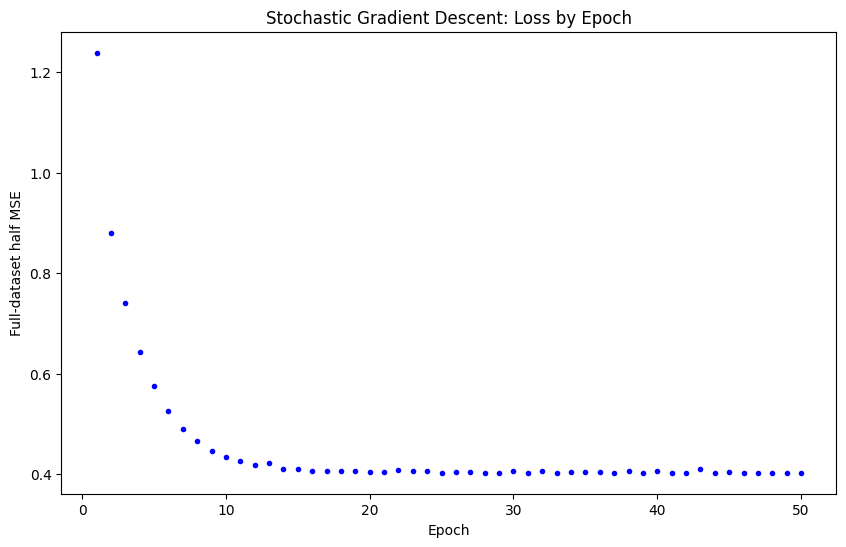

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_ylabel('Full-dataset half MSE')
ax.set_xlabel('Epoch')
ax.plot(range(1, n_iter + 1), cost_history, 'b.')
ax.set_title('Stochastic Gradient Descent: Loss by Epoch')
plt.show()

### Variant 3: Mini-Batch Gradient Descent

**Mini-Batch GD** is the happy medium. It computes the gradient on a small, random subset of the data called a **mini-batch**.

**Pros:**
- A good balance between the stability of Batch GD and the speed of SGD.
- Allows for vectorized implementation, making it very efficient on modern hardware (like GPUs).

**Cons:**
- Introduces a new hyperparameter: the `batch_size`.

This is the **most common variant** used in deep learning today.


In [13]:
def minibatch_gradient_descent(X, y, theta, learning_rate=0.01,
                              iterations=10, batch_size=20):
    """Mini-Batch GD: update parameters using small batches of observations."""
    m = len(y)
    if batch_size < 1:
        raise ValueError("batch_size must be at least 1")

    cost_history = np.zeros(iterations)

    for epoch in range(iterations):
        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):
            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]
            X_batch_b = np.c_[np.ones((len(X_batch), 1)), X_batch]
            errors = X_batch_b @ theta - y_batch
            gradient = (X_batch_b.T @ errors) / len(X_batch)
            theta = theta - learning_rate * gradient

        cost_history[epoch] = cal_cost(theta, np.c_[np.ones((m, 1)), X], y)

    return theta, cost_history


Let's run it.

In [14]:
lr = 0.1
n_iter = 200
y_pred = np.random.randn(2,1)
y_pred, cost_history = minibatch_gradient_descent(X, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.213
y_pred[1]: 2.764
Final error: 0.403


### Visualizing the Loss

The loss curve is less noisy than SGD but not as smooth as Batch GD.

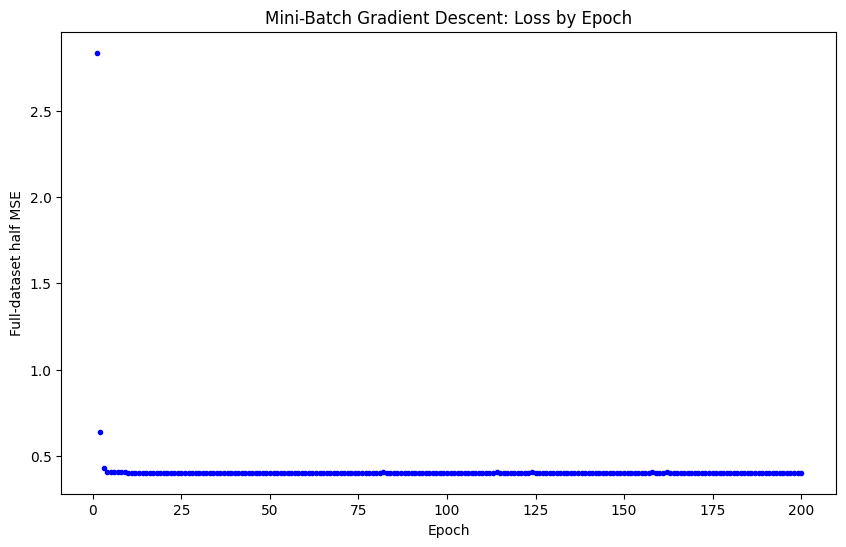

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_ylabel('Full-dataset half MSE')
ax.set_xlabel('Epoch')
ax.plot(range(1, n_iter + 1), cost_history, 'b.')
ax.set_title('Mini-Batch Gradient Descent: Loss by Epoch')
plt.show()

### Visual Comparison of the Learned Models

Let's re-run all three algorithms and plot their final learned lines on the original data. This will give us a better intuition for how they perform.

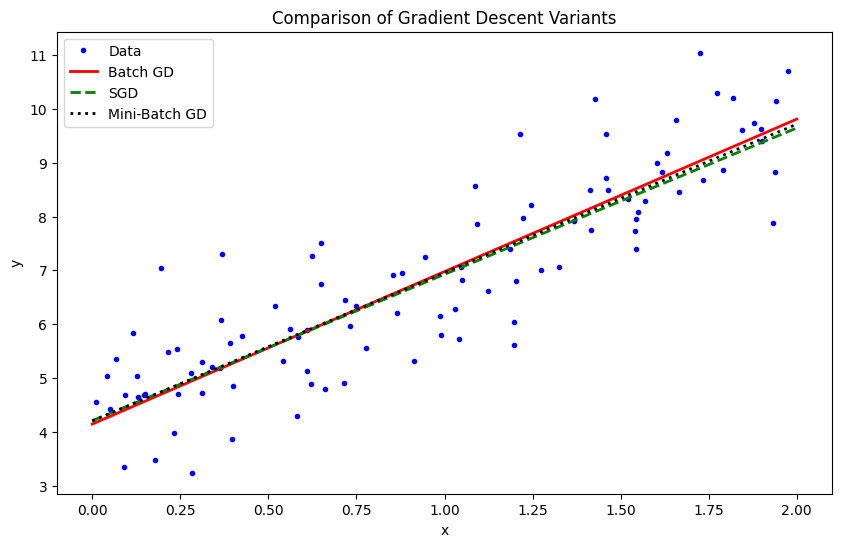

In [16]:
# Rerun all three for comparison
# Batch
lr_batch = 0.1
n_iter_batch = 200
y_pred_batch_final, _, _ = gradient_descent(X_b, y, np.random.randn(2,1), lr_batch, n_iter_batch)

# SGD
lr_sgd = 0.05
n_iter_sgd = 200
y_pred_sgd_final, _ = stocashtic_gradient_descent(X_b, y, np.random.randn(2,1), lr_sgd, n_iter_sgd)

# Mini-Batch
lr_mini = 0.1
n_iter_mini = 200
y_pred_mini_final, _ = minibatch_gradient_descent(X, y, np.random.randn(2,1), lr_mini, n_iter_mini)


# Plotting
plt.figure(figsize=(10, 6))
plt.plot(X, y, 'b.', label='Data')
# Create a set of X values for plotting the lines
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
# Get predictions for the lines
y_predict_batch = X_new_b.dot(y_pred_batch_final)
y_predict_sgd = X_new_b.dot(y_pred_sgd_final)
y_predict_mini = X_new_b.dot(y_pred_mini_final)

plt.plot(X_new, y_predict_batch, 'r-', linewidth=2, label='Batch GD')
plt.plot(X_new, y_predict_sgd, 'g--', linewidth=2, label='SGD')
plt.plot(X_new, y_predict_mini, 'k:', linewidth=2, label='Mini-Batch GD')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Comparison of Gradient Descent Variants')
plt.legend()
plt.show()

As you can see, all three methods find a very good fit to the data. While their training dynamics (the loss curves) are very different, they all achieve the same goal.

### Things to Try Out

1. **Change batch size in mini-batch gradient descent:**
   Try a small size (e.g., `2`) and a large size (e.g., `80`). How does the loss curve change? What happens when the batch size equals the total number of samples?

2. **Test on real datasets:**
   Use a dataset from `sklearn.datasets`, like the **Boston Housing** or **Diabetes** datasets, and see how each variant performs.

3. **Compare learning rates:**
   Test the effects of changing the learning rate. Try a very high and a very low learning rate for each of the three variants. Which one is most sensitive to the learning rate?

4. **Implement a learning rate schedule for SGD:**
   Instead of a fixed learning rate, make it decrease over time (e.g., `lr = initial_lr / (epoch + 1)`). How does this affect the final error and the stability of the loss curve?


## **Additional Critical Thinking Question**



**Which of the following is TRUE, given the optimal learning rate?**

 (i) Batch gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (ii) Stochastic gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (iii) For convex loss functions (i.e. with a bowl shape), batch gradient descent is guaranteed to eventually converge to the global optimum while stochastic gradient descent is not.

 (iv) For convex loss functions (i.e. with a bowl shape), stochastic gradient descent is guaranteed to eventually converge to the global optimum while batch gradient descent is not.

 (v) For convex loss functions (i.e. with a bowl shape), both stochastic gradient descent and batch gradient descent will eventually converge to the global optimum.

 (vi) For convex loss functions (i.e. with a bowl shape), neither stochastic gradient descent nor batch gradient descent are guaranteed to converge to the global optimum.

### Answer



The correct statement is (iii).

**Explanation:**

* A convex loss function has a single minimum, which is the global minimum (like a perfect bowl).

* Batch Gradient Descent calculates the true gradient of the entire dataset. With a suitable learning rate, it will take determined, non-random steps directly towards the minimum. It is therefore guaranteed to converge to the global optimum of a convex function.

* Stochastic Gradient Descent uses a single random point to estimate the gradient. This estimate is noisy and does not point directly at the minimum. Because of this randomness, SGD will not converge to the exact minimum point but will instead perpetually bounce around in the vicinity of the minimum. To make it converge, one typically has to use a learning rate schedule that slowly decreases the learning rate to zero.

* Statements (i) and (ii) are too strong; they don't specify the type of loss function. For a non-convex function (with many local minima), neither is guaranteed to find the global optimum. They might get stuck in a local minimum.

* **Therefore**, for a convex problem, Batch GD is guaranteed to find the optimum, while standard SGD is not guaranteed to land precisely on it.

## Completed Practical Exercises — Things to Try Out

The following experiments answer all four practice prompts using reproducible code. The Boston Housing dataset has been removed from recent versions of scikit-learn, so the **Diabetes** dataset is used for the real-data comparison.

### Exercise 1: Effect of Mini-Batch Size

We compare batch sizes 2, 20, 80, and 100 (the full dataset). A batch size equal to the number of observations makes each mini-batch update use the entire dataset, so it behaves like Batch Gradient Descent.

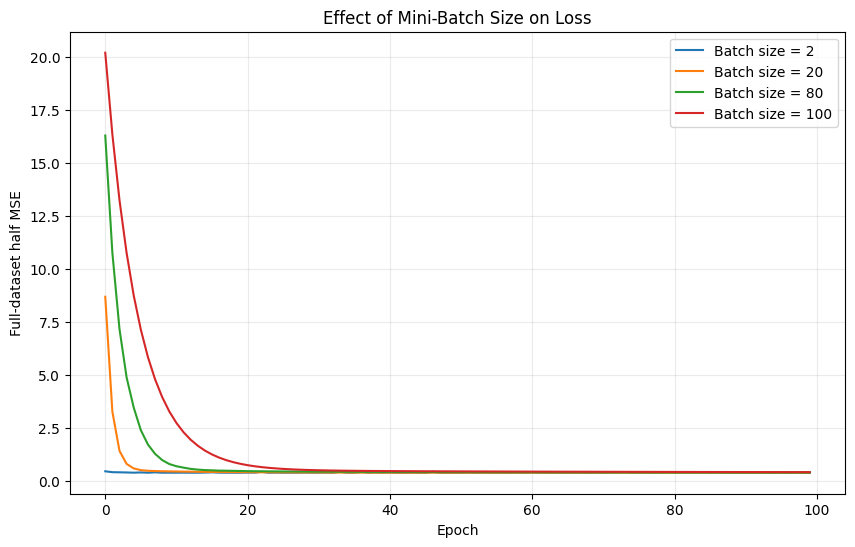

Batch size   2: intercept=4.227, slope=2.808, final half MSE=0.4047
Batch size  20: intercept=4.203, slope=2.784, final half MSE=0.4033
Batch size  80: intercept=4.035, slope=2.929, final half MSE=0.4082
Batch size 100: intercept=3.791, slope=3.144, final half MSE=0.4304


In [17]:
# Compare mini-batch sizes on the original 100-observation dataset
batch_sizes = [2, 20, 80, len(X)]
mini_batch_results = {}

for size in batch_sizes:
    theta_start = np.zeros((2, 1))
    theta_final, costs = minibatch_gradient_descent(
        X, y, theta_start, learning_rate=0.05,
        iterations=100, batch_size=size
    )
    mini_batch_results[size] = (theta_final, costs)

plt.figure(figsize=(10, 6))
for size, (_, costs) in mini_batch_results.items():
    plt.plot(costs, label=f'Batch size = {size}')
plt.xlabel('Epoch')
plt.ylabel('Full-dataset half MSE')
plt.title('Effect of Mini-Batch Size on Loss')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

for size, (theta_final, costs) in mini_batch_results.items():
    print(f'Batch size {size:>3}: intercept={theta_final[0,0]:.3f}, '
          f'slope={theta_final[1,0]:.3f}, final half MSE={costs[-1]:.4f}')

**Observation:** Small batches make more frequent, noisier updates. Larger batches generally produce smoother and more stable loss curves. When batch size equals the full sample count (100 here), the update is equivalent to Batch Gradient Descent, subject to the same learning rate and initialization.

### Exercise 2: Test the Algorithms on a Real Dataset

We use scikit-learn's Diabetes dataset. To keep the exercise aligned with the notebook's single-feature linear-regression example, we use the BMI feature and standardize it. The target is the diabetes disease-progression measure. Each algorithm is compared using the same train/test split and test MSE.

In [18]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

diabetes = load_diabetes()
feature_index = diabetes.feature_names.index('bmi')
X_real = diabetes.data[:, [feature_index]]
y_real = diabetes.target.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_b = np.c_[np.ones((len(X_train_scaled), 1)), X_train_scaled]
X_test_b = np.c_[np.ones((len(X_test_scaled), 1)), X_test_scaled]

# Batch GD
theta_batch, batch_costs, _ = gradient_descent(
    X_train_b, y_train, np.zeros((2, 1)), learning_rate=0.05, iterations=1500
)
# SGD
theta_sgd, sgd_costs = stocashtic_gradient_descent(
    X_train_b, y_train, np.zeros((2, 1)), learning_rate=0.001, iterations=100
)
# Mini-batch GD
theta_mini, mini_costs = minibatch_gradient_descent(
    X_train_scaled, y_train, np.zeros((2, 1)),
    learning_rate=0.01, iterations=300, batch_size=32
)

real_results = []
for name, theta in [('Batch GD', theta_batch), ('SGD', theta_sgd), ('Mini-Batch GD', theta_mini)]:
    predictions = X_test_b @ theta
    test_mse = mean_squared_error(y_test, predictions)
    real_results.append((name, test_mse, theta[0, 0], theta[1, 0]))

print('Diabetes dataset — BMI feature only')
print(f'{"Method":<16} {"Test MSE":>12} {"Intercept":>12} {"BMI coef.":>12}')
for name, mse, intercept, coefficient in real_results:
    print(f'{name:<16} {mse:>12.3f} {intercept:>12.3f} {coefficient:>12.3f}')

Diabetes dataset — BMI feature only
Method               Test MSE    Intercept    BMI coef.
Batch GD             4061.826      153.737       47.141
SGD                  4062.683      153.959       47.188
Mini-Batch GD        4103.382      152.409       48.632


**Observation:** The test MSE measures prediction error on observations not used for training. The three methods may produce slightly different results because SGD and Mini-Batch GD use randomized updates. This is a one-feature demonstration, not a full-feature clinical prediction model.

### Exercise 3: Compare Learning Rates

A very small learning rate makes convergence slow. A suitable learning rate reduces loss efficiently. A very high learning rate can overshoot the minimum or diverge. The experiment below compares learning rates for all three variants.

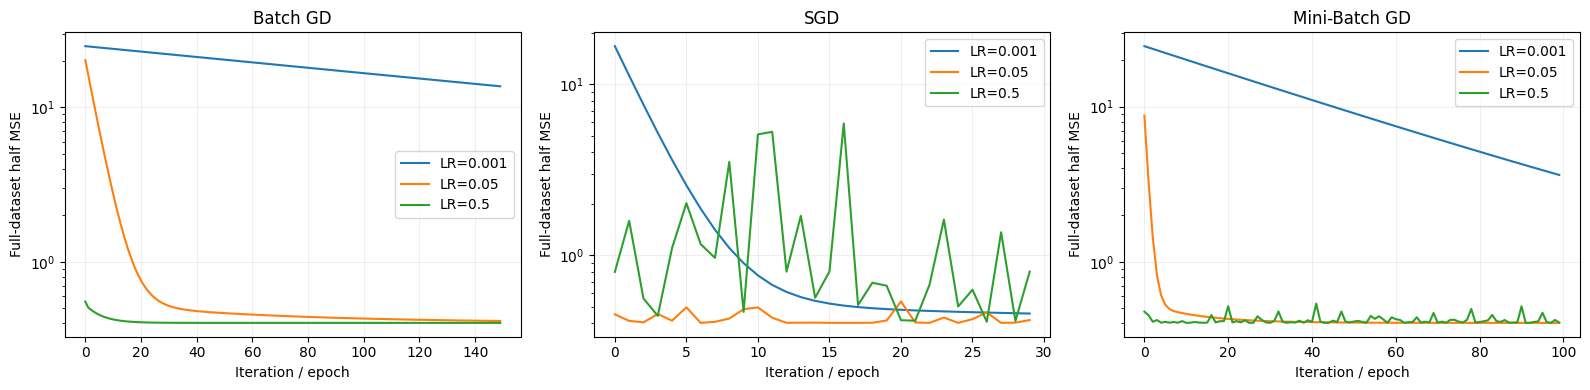

In [19]:
learning_rates = [0.001, 0.05, 0.5]
lr_histories = {}

for rate in learning_rates:
    _, batch_cost, _ = gradient_descent(
        X_b, y, np.zeros((2, 1)), learning_rate=rate, iterations=150
    )
    _, sgd_cost = stocashtic_gradient_descent(
        X_b, y, np.zeros((2, 1)), learning_rate=rate, iterations=30
    )
    _, mini_cost = minibatch_gradient_descent(
        X, y, np.zeros((2, 1)), learning_rate=rate,
        iterations=100, batch_size=20
    )
    lr_histories[rate] = (batch_cost, sgd_cost, mini_cost)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
methods = ['Batch GD', 'SGD', 'Mini-Batch GD']
for ax, method_index, method in zip(axes, range(3), methods):
    for rate, histories in lr_histories.items():
        values = histories[method_index]
        ax.plot(values, label=f'LR={rate}')
    ax.set_title(method)
    ax.set_xlabel('Iteration / epoch')
    ax.set_ylabel('Full-dataset half MSE')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Observation:** The most suitable learning rate depends on the algorithm and data scale. SGD is often more sensitive to the learning rate because each update is based on one observation and is therefore noisy. Mini-batch updates reduce some of that noise. A rate of 0.5 may be too large and can cause instability; the log-scale plot helps display large differences in loss.

### Exercise 4: Learning-Rate Schedule for SGD

Instead of keeping the learning rate fixed, we decrease it each epoch using `lr = initial_lr / (epoch + 1)`. This allows larger updates early in training and smaller updates later, which can improve stability near the minimum.

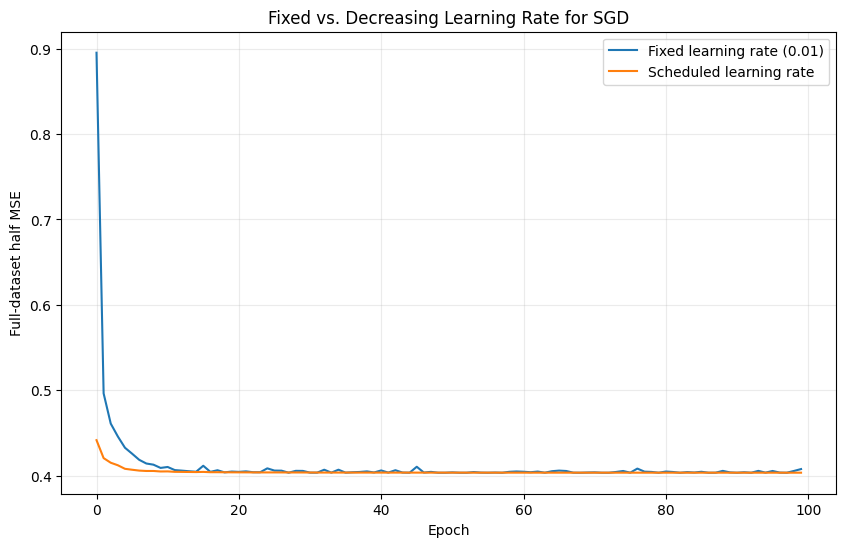

Fixed-rate SGD parameters: [4.17250732 2.72184938]
Scheduled-rate SGD parameters: [4.20050597 2.78194015]
Final fixed-rate half MSE: 0.4076
Final scheduled-rate half MSE: 0.4033
First scheduled rate: 0.05
Last scheduled rate: 0.0005


In [20]:
def scheduled_stochastic_gradient_descent(X, y, theta,
                                           initial_lr=0.05, epochs=100):
    """SGD with a decreasing learning rate: initial_lr / (epoch + 1)."""
    m = len(y)
    costs = np.zeros(epochs)
    rates = np.zeros(epochs)

    for epoch in range(epochs):
        current_lr = initial_lr / (epoch + 1)
        rates[epoch] = current_lr
        for index in np.random.permutation(m):
            X_i = X[index:index + 1]
            y_i = y[index:index + 1]
            theta = theta - current_lr * (X_i.T @ (X_i @ theta - y_i))
        costs[epoch] = cal_cost(theta, X, y)

    return theta, costs, rates

np.random.seed(42)
theta_fixed, fixed_costs = stocashtic_gradient_descent(
    X_b, y, np.zeros((2, 1)), learning_rate=0.01, iterations=100
)
np.random.seed(42)
theta_scheduled, scheduled_costs, learning_rates_by_epoch = scheduled_stochastic_gradient_descent(
    X_b, y, np.zeros((2, 1)), initial_lr=0.05, epochs=100
)

plt.figure(figsize=(10, 6))
plt.plot(fixed_costs, label='Fixed learning rate (0.01)')
plt.plot(scheduled_costs, label='Scheduled learning rate')
plt.xlabel('Epoch')
plt.ylabel('Full-dataset half MSE')
plt.title('Fixed vs. Decreasing Learning Rate for SGD')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print('Fixed-rate SGD parameters:', theta_fixed.ravel())
print('Scheduled-rate SGD parameters:', theta_scheduled.ravel())
print('Final fixed-rate half MSE:', round(fixed_costs[-1], 4))
print('Final scheduled-rate half MSE:', round(scheduled_costs[-1], 4))
print('First scheduled rate:', round(learning_rates_by_epoch[0], 4))
print('Last scheduled rate:', round(learning_rates_by_epoch[-1], 4))

**Observation:** The scheduled learning rate decreases from the initial value to a smaller value as training proceeds. This can reduce late-stage oscillation and improve stability. The final error depends on the initial rate, number of epochs, and random sample order; a schedule is not guaranteed to outperform every well-tuned fixed rate.

## Summary of the Completed Lab

- **Batch Gradient Descent:** calculates each update using the complete training dataset; its loss curve is generally smooth.
- **Stochastic Gradient Descent:** updates using one observation at a time; it can learn quickly but has noisier updates.
- **Mini-Batch Gradient Descent:** updates using a small subset; it balances computational efficiency and update stability.
- **Learning rate:** controls the size of each parameter update and must be selected carefully.
- **Learning-rate schedule:** gradually reduces the step size and can make later training more stable.

The practical exercises above include runnable code, plots, printed results, and observations.